In [18]:
import os
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "nn").exists() else Path.cwd().parent
os.chdir(ROOT)

In [19]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from nn import *
from nn.data import load_image_folder, one_hot
from nn.visualizations import plot_history, plot_digits, plot_confusion_matrix, plot_images

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
os.getcwd()

'/Users/arjunadhithyarr/Documents/z-arjun/numpy-neural-net-play'

In [21]:
from PIL import Image

data_dir = Path("data/cat_dog")
size = 64  

def load_cat_dog(split):
    images, labels = [], []
    for label, name in ((0, "cats"), (1, "dogs")):
        for path in sorted((data_dir / split / name).glob("*.jpg")):
            image = Image.open(path).convert("RGB").resize((size, size))
            images.append(np.asarray(image, dtype=float).reshape(-1) / 255.0)
            labels.append(label)
    return np.stack(images), np.asarray(labels)

X_train, y_train = load_cat_dog("train")
X_test, y_test = load_cat_dog("test")

print("train", X_train.shape, "  test", X_test.shape, "  pixels", X_train.min(), "to", X_train.max())
print("train images per class [cat, dog]", np.bincount(y_train, minlength=2))
print("test images per class  [cat, dog]", np.bincount(y_test, minlength=2))

train (557, 12288)   test (140, 12288)   pixels 0.0 to 1.0
train images per class [cat, dog] [279 278]
test images per class  [cat, dog] [70 70]


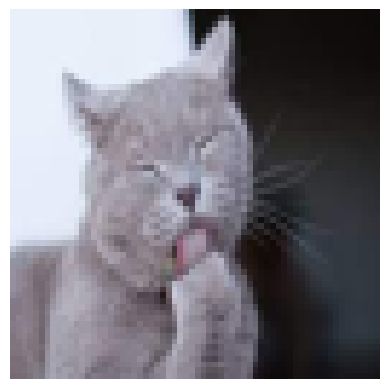

In [30]:
import matplotlib.pyplot as plt
from PIL import Image

train_arr1 = X_train[1] 
train_arr1

img1 = Image.fromarray(train_arr1)

plt.imshow(X_train[1].reshape(64, 64, 3))
plt.axis("off")
plt.show()

In [32]:
X_train[0].shape

(12288,)

## simple small-net
12288 -> 16 -> 1

In [65]:
rng = np.random.default_rng(0)

def scaled_W(n, n_inputs):
    return rng.normal(0, 1 / np.sqrt(n_inputs), (n, n_inputs))

hidden = multipleNeuron(
    n=16, n_inputs=12288, activation=relu,
    W=scaled_W(16, 12288), b=np.zeros(16),
)
output = multipleNeuron(
    n=1, n_inputs=16, activation=sigmoid,
    W=scaled_W(1, 16), b=np.zeros(1),
)
net = stackLayers([hidden, output])

In [66]:
net

stackLayers(12288 -> 16 relu -> 1 sigmoid)

In [67]:
pred = net.forward(X_train[0])
print(pred, binary_cross_entropy([y_train[0]], pred))

[0.48044204] 0.654776896542282


In [68]:
lr = 1e-4
x0, t0 = X_train[0], [y_train[0]]

pred = net.forward(x0)
loss_before = binary_cross_entropy(t0, pred)
net.backward(binary_cross_entropy_derivative(t0, pred))
sgd_step(net, lr)
loss_after = binary_cross_entropy(t0, net.forward(x0))
print(f"{loss_before:.3f} -> {loss_after:.3f}")

0.655 -> 0.630


## Train on 5 epochs

In [69]:
history = train(
    net, X_train, y_train, binary_cross_entropy,
    lr=1e-4, epochs=5, X_val=X_test, Y_val=y_test,
    log_every=1, seed=0,
)

epoch    1  loss 0.6916  acc 0.528  val_loss 0.6943  val_acc 0.457
epoch    2  loss 0.6881  acc 0.544  val_loss 0.6933  val_acc 0.507
epoch    3  loss 0.6856  acc 0.583  val_loss 0.6939  val_acc 0.493
epoch    4  loss 0.6824  acc 0.539  val_loss 0.6941  val_acc 0.500
epoch    5  loss 0.6848  acc 0.549  val_loss 0.7014  val_acc 0.486


## Train on next simgle image (10 Epochs)

In [70]:
rng = np.random.default_rng(0)

def scaled_W(n, n_inputs):
    return rng.normal(0, 1 / np.sqrt(n_inputs), (n, n_inputs))

hidden = multipleNeuron(n=16, n_inputs=12288, activation=relu, W=scaled_W(16, 12288), b=np.zeros(16))
output = multipleNeuron(n=1, n_inputs=16, activation=sigmoid, W=scaled_W(1, 16), b=np.zeros(1))
net = stackLayers([hidden, output])

lr = 1e-3
x0, t0 = X_train[0], [y_train[0]]
loss_before = binary_cross_entropy(t0, net.forward(x0))
net.backward(binary_cross_entropy_derivative(t0, net.forward(x0)))
sgd_step(net, lr)
loss_after = binary_cross_entropy(t0, net.forward(x0))
print(f"{loss_before:.3f} -> {loss_after:.3f}")

0.655 -> 0.468


In [71]:
history = train(
    net, X_train, y_train, binary_cross_entropy,
    lr=lr, epochs=10, X_val=X_test, Y_val=y_test,
    log_every=1, seed=0,
)

epoch    1  loss 0.6913  acc 0.506  val_loss 0.6944  val_acc 0.500
epoch    2  loss 0.6899  acc 0.519  val_loss 0.6953  val_acc 0.521
epoch    3  loss 0.6888  acc 0.569  val_loss 0.6937  val_acc 0.464
epoch    4  loss 0.6839  acc 0.614  val_loss 0.6932  val_acc 0.479
epoch    5  loss 0.6815  acc 0.587  val_loss 0.6970  val_acc 0.500
epoch    6  loss 0.6724  acc 0.580  val_loss 0.6991  val_acc 0.493
epoch    7  loss 0.6642  acc 0.645  val_loss 0.6977  val_acc 0.450
epoch    8  loss 0.6708  acc 0.603  val_loss 0.7009  val_acc 0.507
epoch    9  loss 0.6611  acc 0.619  val_loss 0.7002  val_acc 0.529
epoch   10  loss 0.6465  acc 0.645  val_loss 0.7089  val_acc 0.493


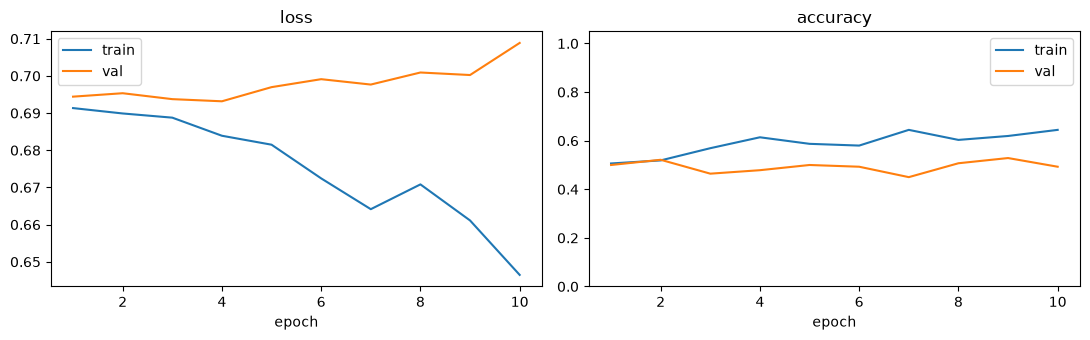

In [72]:
plot_history(history)

In [73]:
def prob(i, X):
    return float(net.forward(X[i])[0])

print("train photo", int(y_train[0]), prob(0, X_train))
print("test photo ", int(y_test[0]), prob(0, X_test))

train photo 0 0.5132961358380094
test photo  0 0.5821772338242828


In [74]:
train_p = predict(net, X_train).ravel()
test_p = predict(net, X_test).ravel()

for name, y, p in (("train", y_train, train_p), ("test", y_test, test_p)):
    cats = p[y == 0]
    dogs = p[y == 1]
    print(name, "cats", np.round(cats[:8], 2), "dogs", np.round(dogs[:8], 2))

train cats [0.51 0.4  0.52 0.5  0.47 0.44 0.44 0.48] dogs [0.54 0.52 0.64 0.55 0.62 0.57 0.67 0.79]
test cats [0.58 0.59 0.53 0.54 0.49 0.52 0.65 0.71] dogs [0.51 0.64 0.48 0.67 0.61 0.53 0.52 0.58]


## Train on next bigger net

In [75]:
size = 32

def load_cat_dog(split):
    images, labels = [], []
    for label, name in ((0, "cats"), (1, "dogs")):
        for path in sorted((data_dir / split / name).glob("*.jpg")):
            image = Image.open(path).convert("L").resize((size, size))
            images.append(np.asarray(image, dtype=float).reshape(-1) / 255.0)
            labels.append(label)
    return np.stack(images), np.asarray(labels)

X_train, y_train = load_cat_dog("train")
X_test, y_test = load_cat_dog("test")
print(X_train.shape, X_test.shape, X_train.min(), X_train.max())

(557, 1024) (140, 1024) 0.0 1.0


In [76]:
rng = np.random.default_rng(0)

def scaled_W(n, n_inputs):
    return rng.normal(0, 1 / np.sqrt(n_inputs), (n, n_inputs))

n_inputs = X_train.shape[1]
hidden = multipleNeuron(n=16, n_inputs=n_inputs, activation=relu, W=scaled_W(16, n_inputs), b=np.zeros(16))
output = multipleNeuron(n=1, n_inputs=16, activation=sigmoid, W=scaled_W(1, 16), b=np.zeros(1))
net = stackLayers([hidden, output])

In [77]:
lr = 1e-3
x0, t0 = X_train[0], [y_train[0]]
loss_before = binary_cross_entropy(t0, net.forward(x0))
net.backward(binary_cross_entropy_derivative(t0, net.forward(x0)))
sgd_step(net, lr)
loss_after = binary_cross_entropy(t0, net.forward(x0))
print(f"{loss_before:.3f} -> {loss_after:.3f}")

0.465 -> 0.436


In [78]:
history = train(
    net, X_train, y_train, binary_cross_entropy,
    lr=lr, epochs=10, X_val=X_test, Y_val=y_test,
    log_every=1, seed=0,
)

epoch    1  loss 0.6910  acc 0.530  val_loss 0.7109  val_acc 0.471
epoch    2  loss 0.6813  acc 0.589  val_loss 0.7044  val_acc 0.457
epoch    3  loss 0.6775  acc 0.591  val_loss 0.7053  val_acc 0.493
epoch    4  loss 0.6739  acc 0.616  val_loss 0.7068  val_acc 0.450
epoch    5  loss 0.6750  acc 0.583  val_loss 0.7116  val_acc 0.479
epoch    6  loss 0.6692  acc 0.582  val_loss 0.7116  val_acc 0.486
epoch    7  loss 0.6658  acc 0.645  val_loss 0.7110  val_acc 0.443
epoch    8  loss 0.6661  acc 0.598  val_loss 0.7137  val_acc 0.479
epoch    9  loss 0.6650  acc 0.610  val_loss 0.7135  val_acc 0.493
epoch   10  loss 0.6636  acc 0.594  val_loss 0.7184  val_acc 0.493


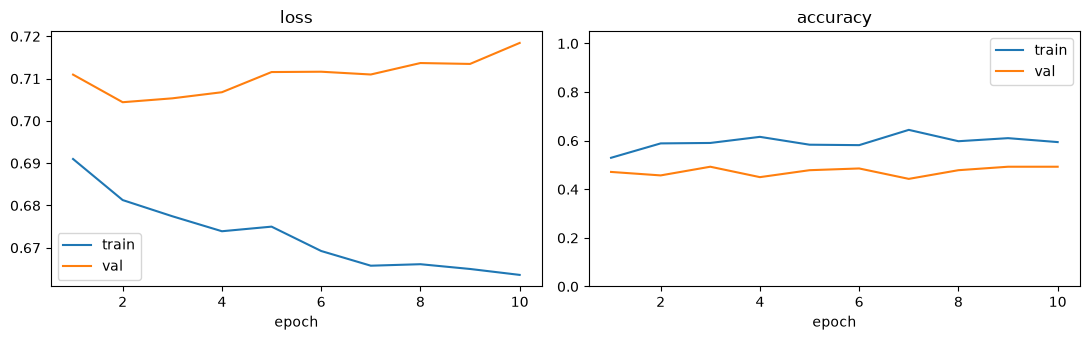

In [79]:
plot_history(history)

## Eight filters of 3×3 slide across the 32×32 photo, stepping by 2. 
## The same 9 weights are reused at every position, then the 1,800 numbers go into the same 16-unit network as before.

In [81]:
from nn.conv import convLayer

size = 32

def load_gray(split):
    images, labels = [], []
    for label, name in ((0, "cats"), (1, "dogs")):
        for path in sorted((data_dir / split / name).glob("*.jpg")):
            image = Image.open(path).convert("L").resize((size, size))
            images.append(np.asarray(image, dtype=float).reshape(-1) / 255.0)
            labels.append(label)
    return np.stack(images), np.asarray(labels)

X_train, y_train = load_gray("train")
X_test, y_test = load_gray("test")
print(X_train.shape, X_test.shape, X_train.min(), X_train.max())

(557, 1024) (140, 1024) 0.0 1.0


In [82]:
rng = np.random.default_rng(0)

def scaled_W(shape):
    return rng.normal(0, 1 / np.sqrt(np.prod(shape[1:])), shape)

conv = convLayer(
    n_filters=8, side=size, kernel=3, stride=2, activation=relu,
    W=scaled_W((8, 3, 3)), b=np.zeros(8),
)
hidden = multipleNeuron(
    n=16, n_inputs=conv.n, activation=relu,
    W=scaled_W((16, conv.n)), b=np.zeros(16),
)
output = multipleNeuron(
    n=1, n_inputs=16, activation=sigmoid,
    W=scaled_W((1, 16)), b=np.zeros(1),
)
net = stackLayers([conv, hidden, output])
print(net)

stackLayers(1024 -> 1800 conv relu -> 16 relu -> 1 sigmoid)


In [83]:
lr = 1e-3
x0, t0 = X_train[0], [y_train[0]]
loss_before = binary_cross_entropy(t0, net.forward(x0))
net.backward(binary_cross_entropy_derivative(t0, net.forward(x0)))
sgd_step(net, lr)
loss_after = binary_cross_entropy(t0, net.forward(x0))
print(f"{loss_before:.3f} -> {loss_after:.3f}")

0.415 -> 0.363


In [84]:
history = train(
    net, X_train, y_train, binary_cross_entropy,
    lr=lr, epochs=10, X_val=X_test, Y_val=y_test,
    log_every=1, seed=0,
)

epoch    1  loss 0.6919  acc 0.503  val_loss 0.6946  val_acc 0.507
epoch    2  loss 0.6902  acc 0.537  val_loss 0.6941  val_acc 0.450
epoch    3  loss 0.6871  acc 0.576  val_loss 0.6921  val_acc 0.529
epoch    4  loss 0.6861  acc 0.592  val_loss 0.6936  val_acc 0.493
epoch    5  loss 0.6843  acc 0.560  val_loss 0.6930  val_acc 0.464
epoch    6  loss 0.6832  acc 0.555  val_loss 0.6933  val_acc 0.450
epoch    7  loss 0.6766  acc 0.583  val_loss 0.6926  val_acc 0.507
epoch    8  loss 0.6721  acc 0.627  val_loss 0.6952  val_acc 0.443
epoch    9  loss 0.6739  acc 0.573  val_loss 0.6927  val_acc 0.486
epoch   10  loss 0.6749  acc 0.569  val_loss 0.6983  val_acc 0.543


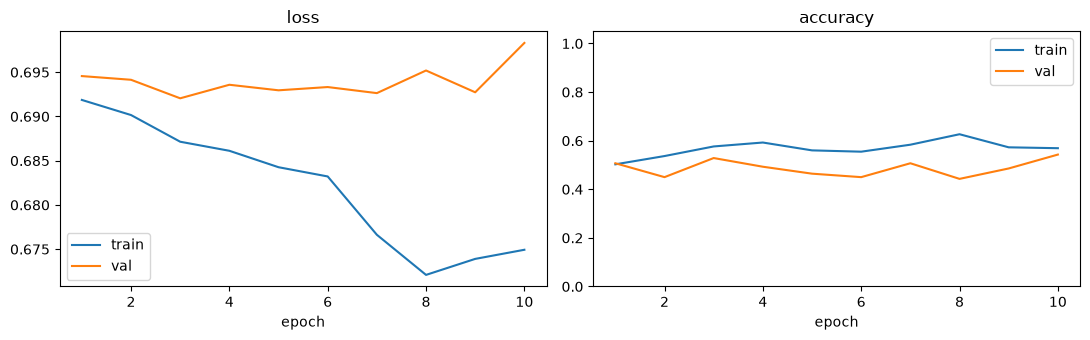

In [85]:
plot_history(history)

## Two convolutions. The first 3×3 reads the photo. 
## The second 3×3 reads a neighborhood of those eight maps, which covers a 7×7 patch of the original photo. The 16-unit layer after that is unchanged.

In [86]:
from nn.conv import convLayer

size = 32

def load_gray(split):
    images, labels = [], []
    for label, name in ((0, "cats"), (1, "dogs")):
        for path in sorted((data_dir / split / name).glob("*.jpg")):
            image = Image.open(path).convert("L").resize((size, size))
            images.append(np.asarray(image, dtype=float).reshape(-1) / 255.0)
            labels.append(label)
    return np.stack(images), np.asarray(labels)

X_train, y_train = load_gray("train")
X_test, y_test = load_gray("test")
print(X_train.shape, X_test.shape, X_train.min(), X_train.max())

(557, 1024) (140, 1024) 0.0 1.0


In [87]:
rng = np.random.default_rng(0)

def scaled_W(shape):
    return rng.normal(0, 1 / np.sqrt(np.prod(shape[1:])), shape)

conv1 = convLayer(
    n_filters=8, side=size, kernel=3, stride=2, in_channels=1, activation=relu,
    W=scaled_W((8, 1, 3, 3)), b=np.zeros(8),
)
conv2 = convLayer(
    n_filters=16, side=conv1.out_side, kernel=3, stride=2,
    in_channels=conv1.n_filters, activation=relu,
    W=scaled_W((16, conv1.n_filters, 3, 3)), b=np.zeros(16),
)
hidden = multipleNeuron(
    n=16, n_inputs=conv2.n, activation=relu,
    W=scaled_W((16, conv2.n)), b=np.zeros(16),
)
output = multipleNeuron(
    n=1, n_inputs=16, activation=sigmoid,
    W=scaled_W((1, 16)), b=np.zeros(1),
)
net = stackLayers([conv1, conv2, hidden, output])
print(net)

stackLayers(1024 -> 1800 conv relu -> 784 conv relu -> 16 relu -> 1 sigmoid)


In [88]:
lr = 1e-3
x0, t0 = X_train[0], [y_train[0]]
loss_before = binary_cross_entropy(t0, net.forward(x0))
net.backward(binary_cross_entropy_derivative(t0, net.forward(x0)))
sgd_step(net, lr)
loss_after = binary_cross_entropy(t0, net.forward(x0))
print(f"{loss_before:.3f} -> {loss_after:.3f}")

0.812 -> 0.795


In [89]:
history = train(
    net, X_train, y_train, binary_cross_entropy,
    lr=lr, epochs=10, X_val=X_test, Y_val=y_test,
    log_every=1, seed=0,
)

epoch    1  loss 0.6879  acc 0.551  val_loss 0.6978  val_acc 0.486
epoch    2  loss 0.6859  acc 0.567  val_loss 0.6967  val_acc 0.493
epoch    3  loss 0.6838  acc 0.576  val_loss 0.6986  val_acc 0.493
epoch    4  loss 0.6828  acc 0.569  val_loss 0.7017  val_acc 0.493
epoch    5  loss 0.6823  acc 0.575  val_loss 0.7005  val_acc 0.450
epoch    6  loss 0.6797  acc 0.566  val_loss 0.7064  val_acc 0.486
epoch    7  loss 0.6761  acc 0.619  val_loss 0.7020  val_acc 0.436
epoch    8  loss 0.6757  acc 0.585  val_loss 0.7041  val_acc 0.457
epoch    9  loss 0.6782  acc 0.578  val_loss 0.7005  val_acc 0.529
epoch   10  loss 0.6732  acc 0.580  val_loss 0.7120  val_acc 0.464


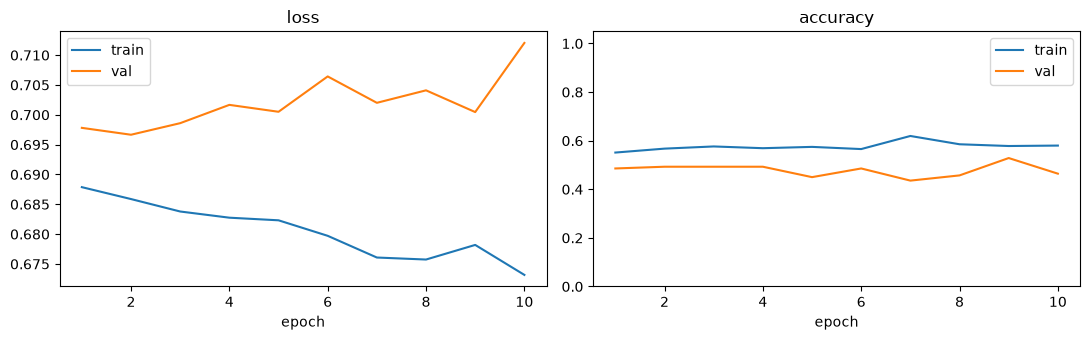

In [90]:
plot_history(history)

## Eight filters, then eight filters, then one sigmoid. 
## The 7×7 maps go straight into that sigmoid. The 16-unit layer is gone, so there is no longer a private weight for every spot times 16.

In [91]:
from nn.conv import convLayer

size = 32

def load_gray(split):
    images, labels = [], []
    for label, name in ((0, "cats"), (1, "dogs")):
        for path in sorted((data_dir / split / name).glob("*.jpg")):
            image = Image.open(path).convert("L").resize((size, size))
            images.append(np.asarray(image, dtype=float).reshape(-1) / 255.0)
            labels.append(label)
    return np.stack(images), np.asarray(labels)

X_train, y_train = load_gray("train")
X_test, y_test = load_gray("test")
print(X_train.shape, X_test.shape, X_train.min(), X_train.max())

(557, 1024) (140, 1024) 0.0 1.0


In [92]:
rng = np.random.default_rng(0)

def scaled_W(shape):
    return rng.normal(0, 1 / np.sqrt(np.prod(shape[1:])), shape)

conv1 = convLayer(
    n_filters=8, side=size, kernel=3, stride=2, in_channels=1, activation=relu,
    W=scaled_W((8, 1, 3, 3)), b=np.zeros(8),
)
conv2 = convLayer(
    n_filters=8, side=conv1.out_side, kernel=3, stride=2,
    in_channels=conv1.n_filters, activation=relu,
    W=scaled_W((8, conv1.n_filters, 3, 3)), b=np.zeros(8),
)
output = multipleNeuron(
    n=1, n_inputs=conv2.n, activation=sigmoid,
    W=scaled_W((1, conv2.n)), b=np.zeros(1),
)
net = stackLayers([conv1, conv2, output])
print(net)

stackLayers(1024 -> 1800 conv relu -> 392 conv relu -> 1 sigmoid)


In [93]:
lr = 1e-3
x0, t0 = X_train[0], [y_train[0]]
loss_before = binary_cross_entropy(t0, net.forward(x0))
net.backward(binary_cross_entropy_derivative(t0, net.forward(x0)))
sgd_step(net, lr)
loss_after = binary_cross_entropy(t0, net.forward(x0))
print(f"{loss_before:.3f} -> {loss_after:.3f}")

0.701 -> 0.694


epoch    1  loss 0.6935  acc 0.499  val_loss 0.6925  val_acc 0.493
epoch    2  loss 0.6920  acc 0.512  val_loss 0.6929  val_acc 0.479
epoch    3  loss 0.6911  acc 0.528  val_loss 0.6936  val_acc 0.493
epoch    4  loss 0.6904  acc 0.551  val_loss 0.6936  val_acc 0.464
epoch    5  loss 0.6895  acc 0.533  val_loss 0.6935  val_acc 0.514
epoch    6  loss 0.6887  acc 0.546  val_loss 0.6935  val_acc 0.543
epoch    7  loss 0.6878  acc 0.555  val_loss 0.6939  val_acc 0.536
epoch    8  loss 0.6868  acc 0.569  val_loss 0.6946  val_acc 0.529
epoch    9  loss 0.6861  acc 0.571  val_loss 0.6949  val_acc 0.514
epoch   10  loss 0.6853  acc 0.580  val_loss 0.6943  val_acc 0.471
epoch   11  loss 0.6844  acc 0.564  val_loss 0.6946  val_acc 0.500
epoch   12  loss 0.6834  acc 0.589  val_loss 0.6950  val_acc 0.521
epoch   13  loss 0.6825  acc 0.600  val_loss 0.6952  val_acc 0.521
epoch   14  loss 0.6814  acc 0.594  val_loss 0.6951  val_acc 0.493
epoch   15  loss 0.6801  acc 0.610  val_loss 0.6958  val_acc 0

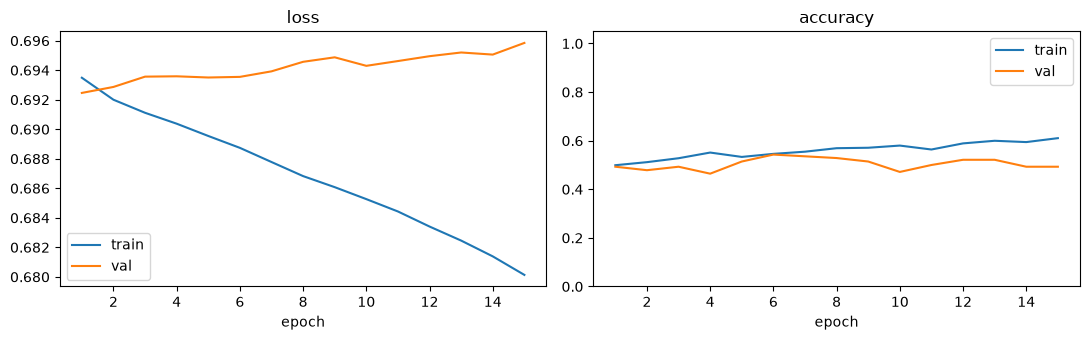

In [94]:
history = train(
    net, X_train, y_train, binary_cross_entropy,
    lr=lr, epochs=15, X_val=X_test, Y_val=y_test,
    log_every=1, seed=0,
)
plot_history(history)